In [ ]:
# Write a program to generate following noises using equations derived
# from PDFs of noise distributions. Compare your output with those
# generated using inbuilt function imnoise. Plot the histograms of generated
# noise to determine the shape of the distribution.
# 1. Uniform noise
# 2. Gaussian noise
# 3. Erlang noise
# 4. Exponential noise
# 5. Rayleigh noise

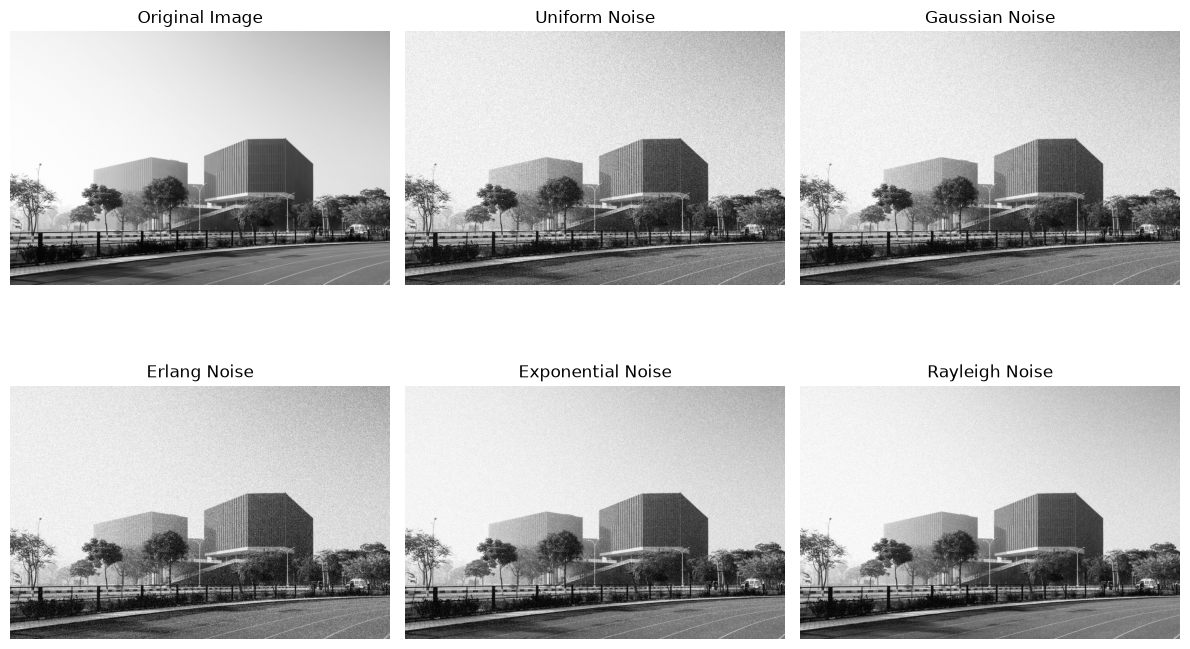

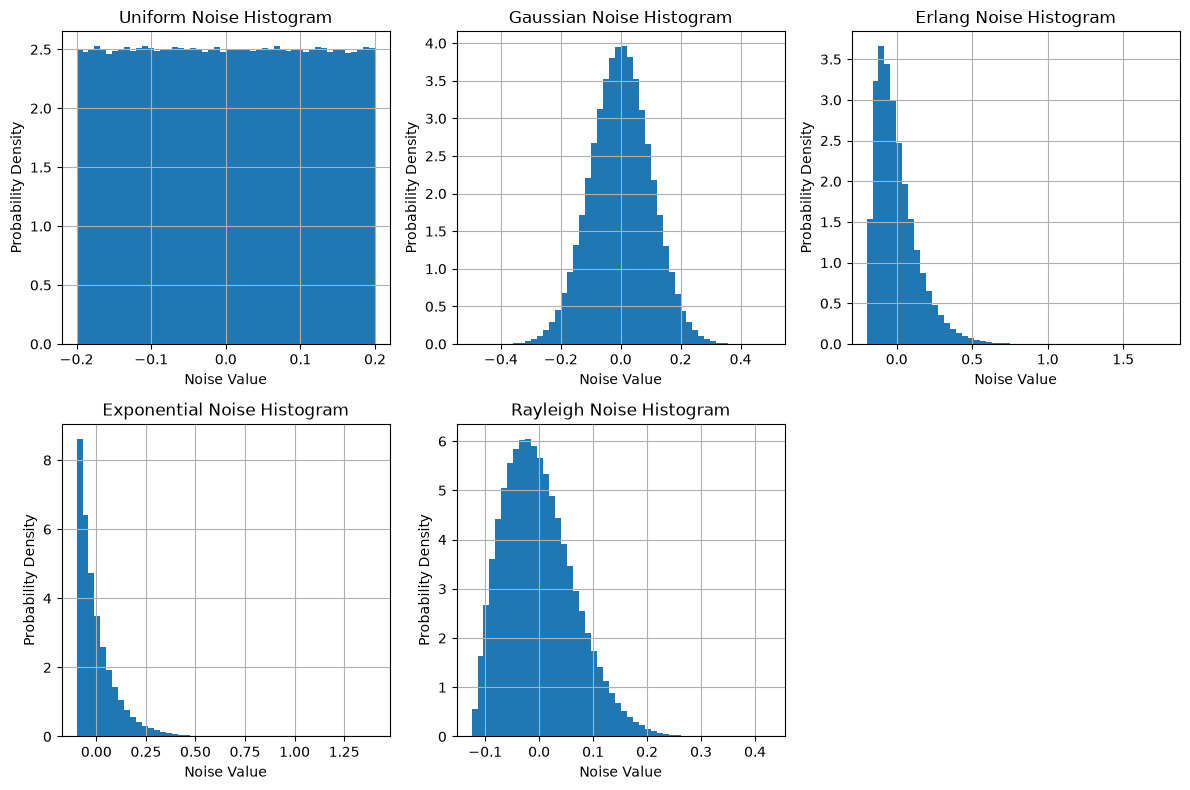

In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread('image.jpg', 0)

# Convert image into float format (0 to 1)
img = img.astype(np.float32) / 255.0

# Image dimensions
rows, cols = img.shape

# Set random seed
np.random.seed(42)

# Parameters
a = -0.2
b = 0.2
mean = 0
sigma = 0.1
alpha = 2
beta = 0.1
rayleigh_sigma = 0.1

# 1. UNIFORM NOISE
uniform_noise = a + (b - a) * np.random.rand(rows, cols)
uniform_img = np.clip(img + uniform_noise, 0, 1)

# 2. GAUSSIAN NOISE
gaussian_noise = np.random.normal(mean, sigma, (rows, cols))
gaussian_img = np.clip(img + gaussian_noise, 0, 1)

# 3. ERLANG NOISE
erlang_noise = np.random.gamma(alpha, beta, (rows, cols))
erlang_noise = erlang_noise - alpha * beta
erlang_img = np.clip(img + erlang_noise, 0, 1)

# 4. EXPONENTIAL NOISE
exponential_noise = np.random.exponential(beta, (rows, cols))
exponential_noise = exponential_noise - beta
exponential_img = np.clip(img + exponential_noise, 0, 1)

# 5. RAYLEIGH NOISE
u1 = np.random.rand(rows, cols)
u2 = np.random.rand(rows, cols)

rayleigh_noise = rayleigh_sigma * np.sqrt(
    -2 * np.log(1 - u1)
)
rayleigh_noise = rayleigh_noise - rayleigh_sigma * np.sqrt(np.pi / 2)

rayleigh_img = np.clip(img + rayleigh_noise, 0, 1)


# Display original and noisy images
images = [
    img,
    uniform_img,
    gaussian_img,
    erlang_img,
    exponential_img,
    rayleigh_img
]

titles = [
    'Original Image',
    'Uniform Noise',
    'Gaussian Noise',
    'Erlang Noise',
    'Exponential Noise',
    'Rayleigh Noise'
]

plt.figure(figsize=(12, 8))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=1)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()


# Plot histograms of generated noise
noises = [
    uniform_noise,
    gaussian_noise,
    erlang_noise,
    exponential_noise,
    rayleigh_noise
]

noise_titles = [
    'Uniform Noise Histogram',
    'Gaussian Noise Histogram',
    'Erlang Noise Histogram',
    'Exponential Noise Histogram',
    'Rayleigh Noise Histogram'
]

plt.figure(figsize=(12, 8))

for i in range(5):
    plt.subplot(2, 3, i + 1)
    plt.hist(noises[i].ravel(), bins=50, density=True)
    plt.title(noise_titles[i])
    plt.xlabel('Noise Value')
    plt.ylabel('Probability Density')
    plt.grid()

plt.tight_layout()
plt.show()
